<a href="https://colab.research.google.com/github/brightspark0072-dot/HE/blob/main/PHE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ready.
AES ciphertext of 5: 66c6d6089b902f5f0e419e2c6259b3e7
AES ciphertext of 7: 64a92b0991fa4ff0b69f8564936e6acf
Decrypting each works: 5 7

Decrypting the 'sum' of the ciphertexts gives: 156385957506668770674609401952510945622
Expected 12.  Meaningless? -> True
Paillier loaded.
Public key n : 0x92da49f3…f2b9c35b  (1024 bits)  <- may be shared
Secret key   : kept by the data owner, never sent

E(5) = 0x12975637…55a3e244  (2045 bits)
E(7) = 0x45da2ac9…f4fb2309  (2047 bits)

Encrypting 5 a second time gives a different ciphertext:
E(5) = 0x354c1f0a…e1332f8c  (2046 bits)
Same ciphertext? False | both decrypt to 5 and 5
Cloud returns a ciphertext: 0x30322b84…c0e989c1  (2046 bits)
The cloud has no idea this hides 12.
D( E(5) ⊞ E(7) ) = 12

5 + 7 = 12, computed without the server ever seeing 5 or 7.
Ordinary +  ->  decrypts to: 0x81d527…8c69c9  (1020 bits)
Correct ⊞ (multiply mod n²)  ->  decrypts to: 12
Decrypted total : 492 (check: 492 )
Average         : 98.4
92 x 3 computed on cipherte

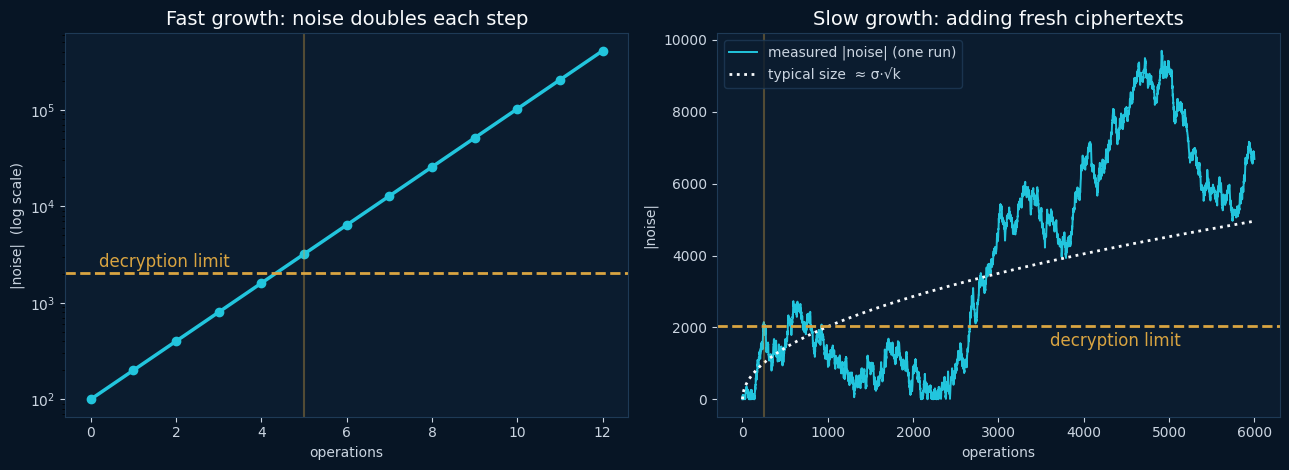

In [ ]:
"""
The Invisible Calculator: real homomorphic-encryption demo .
Needs Python 3.9+ with numpy, matplotlib and cryptography. Same content as the Colab notebook.
Part 3 saves noise_growth.png and opens a plot window (close it to finish).
"""

import math, os, secrets
import numpy as np
import matplotlib.pyplot as plt

def short(x, k=8):
    """Show a big integer compactly: first/last hex digits and bit length."""
    h = format(x, 'x')
    return f"0x{h[:k]}…{h[-k:]}  ({x.bit_length()} bits)"

print("Ready.")

from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes

aes_key = os.urandom(32)          # AES-256 key (symmetric)
iv      = os.urandom(16)

def aes_encrypt(n):
    enc = Cipher(algorithms.AES(aes_key), modes.CBC(iv)).encryptor()
    return enc.update(n.to_bytes(16, 'big')) + enc.finalize()

def aes_decrypt(ct):
    dec = Cipher(algorithms.AES(aes_key), modes.CBC(iv)).decryptor()
    return int.from_bytes(dec.update(ct) + dec.finalize(), 'big')

c5, c7 = aes_encrypt(5), aes_encrypt(7)
print("AES ciphertext of 5:", c5.hex())
print("AES ciphertext of 7:", c7.hex())
print("Decrypting each works:", aes_decrypt(c5), aes_decrypt(c7))

# A server that treats the ciphertexts as ordinary numbers and adds them:
naive_sum = (int.from_bytes(c5, 'big') + int.from_bytes(c7, 'big')) % 2**128
result = aes_decrypt(naive_sum.to_bytes(16, 'big'))
print("\nDecrypting the 'sum' of the ciphertexts gives:", result)
print("Expected 12.  Meaningless? ->", result != 12)

# ---- Paillier, written from scratch (clarity over speed) -------------------
def is_probable_prime(n, rounds=40):
    if n < 2: return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0: return n == p
    d, r = n - 1, 0
    while d % 2 == 0: d //= 2; r += 1
    for _ in range(rounds):                       # Miller–Rabin
        a = secrets.randbelow(n - 3) + 2
        x = pow(a, d, n)
        if x in (1, n - 1): continue
        for _ in range(r - 1):
            x = pow(x, 2, n)
            if x == n - 1: break
        else:
            return False
    return True

def gen_prime(bits):
    while True:
        c = secrets.randbits(bits) | (1 << (bits - 1)) | 1
        if is_probable_prime(c): return c

def paillier_keygen(n_bits=1024):
    while True:
        p, q = gen_prime(n_bits // 2), gen_prime(n_bits // 2)
        if p != q and math.gcd(p * q, (p - 1) * (q - 1)) == 1: break
    n = p * q
    lam = math.lcm(p - 1, q - 1)
    mu = pow(lam, -1, n)
    public_key = n                      # safe to share
    secret_key = (n, lam, mu)           # never leaves the data owner
    return public_key, secret_key

def encrypt(public_key, m):
    n = public_key; n2 = n * n
    assert 0 <= m < n
    while True:
        r = secrets.randbelow(n - 1) + 1            # fresh randomness each time
        if math.gcd(r, n) == 1: break
    return ((1 + m * n) * pow(r, n, n2)) % n2

def decrypt(secret_key, c):
    n, lam, mu = secret_key
    u = pow(c, lam, n * n)
    return (((u - 1) // n) * mu) % n

class UntrustedCloud:
    """The server. It is constructed from the PUBLIC key only."""
    def __init__(self, public_key):
        self.n = public_key; self.n2 = public_key ** 2
    def add(self, c1, c2):                 # the encrypted addition  ⊞
        return (c1 * c2) % self.n2
    def scale(self, c, k):                 # encrypted value × a PLAIN constant
        return pow(c, k, self.n2)

print("Paillier loaded.")

public_key, secret_key = paillier_keygen(1024)
print("Public key n :", short(public_key), " <- may be shared")
print("Secret key   : kept by the data owner, never sent\n")

E5 = encrypt(public_key, 5)
E7 = encrypt(public_key, 7)
print("E(5) =", short(E5))
print("E(7) =", short(E7))

# Encryption is randomised: same plaintext, different ciphertext every time
E5_again = encrypt(public_key, 5)
print("\nEncrypting 5 a second time gives a different ciphertext:")
print("E(5) =", short(E5_again))
print("Same ciphertext?", E5 == E5_again, "| both decrypt to", decrypt(secret_key, E5), "and", decrypt(secret_key, E5_again))

cloud = UntrustedCloud(public_key)
assert not hasattr(cloud, "lam") and not hasattr(cloud, "secret_key")   # no secret key on the server

E_sum = cloud.add(E5, E7)       # E(5) ⊞ E(7)
print("Cloud returns a ciphertext:", short(E_sum))
print("The cloud has no idea this hides 12.")

result = decrypt(secret_key, E_sum)
print("D( E(5) ⊞ E(7) ) =", result)
assert result == 12
print("\n5 + 7 = 12, computed without the server ever seeing 5 or 7.")

wrong = (E5 + E7) % (public_key ** 2)          # ordinary addition of ciphertexts
print("Ordinary +  ->  decrypts to:", short(decrypt(secret_key, wrong), 6))
print("Correct ⊞ (multiply mod n²)  ->  decrypts to:", decrypt(secret_key, E_sum))

readings = [92, 105, 88, 110, 97]                       # mg/dL, private
encrypted_readings = [encrypt(public_key, r) for r in readings]

# ---- cloud side: sees only ciphertexts ----
encrypted_total = encrypted_readings[0]
for c in encrypted_readings[1:]:
    encrypted_total = cloud.add(encrypted_total, c)
encrypted_x3 = cloud.scale(encrypted_readings[0], 3)     # E(92) scaled by the plain constant 3

# ---- owner side ----
total = decrypt(secret_key, encrypted_total)
print("Decrypted total :", total, "(check:", sum(readings), ")")
print("Average         :", total / len(readings))
print("92 x 3 computed on ciphertext:", decrypt(secret_key, encrypted_x3))
assert total == sum(readings)

plain_bytes  = 1                                    # the number 5 fits in one byte
cipher_bytes = (E5.bit_length() + 7) // 8
print(f"Plaintext 5  : {plain_bytes} byte")
print(f"Ciphertext   : {cipher_bytes} bytes  (~{cipher_bytes // plain_bytes}x larger, even with this small demo key)")

rng = np.random.default_rng(2026)
N, q, t, sigma = 32, 2**20, 256, 64        # dimension, modulus, plaintext modulus, noise std
delta = q // t                              # scaling factor Δ = 4096
threshold = delta // 2                      # decryption fails once |noise| > Δ/2 = 2048

s = rng.integers(-1, 2, N)                  # secret key

def centered(x):                            # map to (-q/2, q/2]
    return ((int(x) + q // 2) % q) - q // 2

def enc(m):
    a = rng.integers(0, q, N)
    e = int(round(rng.normal(0, sigma)))
    return a, (int(a @ s) + e + delta * m) % q

def phase(ct):
    a, b = ct
    return (b - int(a @ s)) % q

def dec(ct):
    return int(round(phase(ct) / delta)) % t

def noise_of(ct, expected):                 # measured noise = what is left after removing Δ·m
    return centered(phase(ct) - delta * expected)

def add(c1, c2):                            # homomorphic addition
    return (c1[0] + c2[0]) % q, (c1[1] + c2[1]) % q

# Homomorphic addition works: 5 + 7
c = add(enc(5), enc(7))
print("Decrypted 5 + 7 =", dec(c), "| noise in the result:", noise_of(c, 12),
      f"| limit ±{threshold}")

# --- slow growth: add a fresh E(1) each step
ct, expected = enc(0), 0
add_noise, add_fail = [0], None
for k in range(1, 6001):
    ct = add(ct, enc(1)); expected = (expected + 1) % t
    add_noise.append(abs(noise_of(ct, expected)))
    if add_fail is None and dec(ct) != expected: add_fail = k

# --- fast growth: double the ciphertext each step
ct, expected = enc(1), 1
dbl_noise, dbl_fail = [abs(noise_of(ct, expected))], None
for k in range(1, 13):
    ct = add(ct, ct); expected = (2 * expected) % t
    dbl_noise.append(abs(noise_of(ct, expected)))
    if dbl_fail is None and dec(ct) != expected: dbl_fail = k

print("Fresh noise per ciphertext ~", sigma, "  | decryption limit:", threshold)
print("Fast growth (doubling): first wrong decryption at step", dbl_fail)
print("Slow growth (adding)  : first wrong decryption at step", add_fail)

BG, FG, CYAN, AMBER = "#071525", "#F8FAFC", "#22C5DD", "#D9A441"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=BG)
for ax in axes:
    ax.set_facecolor("#0B1C2F")
    for sp in ax.spines.values(): sp.set_color("#1E3A56")
    ax.tick_params(colors="#CBD5E1"); ax.xaxis.label.set_color("#CBD5E1"); ax.yaxis.label.set_color("#CBD5E1")

ax = axes[0]
ax.plot(range(len(dbl_noise)), np.maximum(dbl_noise, 1), "o-", color=CYAN, lw=2.5)
ax.axhline(threshold, color=AMBER, ls="--", lw=2); ax.set_yscale("log")
ax.text(0.2, threshold * 1.15, "decryption limit", color=AMBER, fontsize=12)
if dbl_fail: ax.axvline(dbl_fail, color=AMBER, alpha=.35)
ax.set_title("Fast growth: noise doubles each step", color=FG, fontsize=14)
ax.set_xlabel("operations"); ax.set_ylabel("|noise|  (log scale)")

ax = axes[1]
ks = np.arange(len(add_noise))
ax.plot(ks, add_noise, color=CYAN, lw=1.4, label="measured |noise| (one run)")
ax.plot(ks, sigma * np.sqrt(ks), color=FG, lw=2, ls=":", label="typical size  ≈ σ·√k")
ax.axhline(threshold, color=AMBER, ls="--", lw=2)
ax.text(3600, threshold * 0.72, "decryption limit", color=AMBER, fontsize=12)
ax.legend(facecolor="#0B1C2F", edgecolor="#1E3A56", labelcolor="#CBD5E1", loc="upper left")
if add_fail: ax.axvline(add_fail, color=AMBER, alpha=.35)
ax.set_title("Slow growth: adding fresh ciphertexts", color=FG, fontsize=14)
ax.set_xlabel("operations"); ax.set_ylabel("|noise|")

plt.tight_layout()
plt.savefig("noise_growth.png", dpi=160, facecolor=BG)
plt.show()
